In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
DATA_PATH = "../data/CS_S0_S1_S2_S3_S4_S6A_S6B_S6C_Person.dta"

In [2]:
raw = pd.read_stata(DATA_PATH, convert_categoricals=False)
print("rows, columns:", raw.shape)
print("households:", raw["hhid"].nunique())

rows, columns: (62110, 157)
households: 15054


In [3]:
# only people who attended school in the last 12 months were asked about school costs
students = raw[raw["s4aq7"] == 1].copy()

parts = ["s4aq14a", "s4aq14b", "s4aq14c", "s4aq14d", "s4aq14e", "s4aq14f", "s4aq14g"]
has_parts = students["s4aq14a"].notna()
has_total = students["s4aq14h"].notna()

print("students:", len(students))
print("with the 7 parts:", has_parts.sum(), "| with only the total:", has_total.sum())
print("with both:", (has_parts & has_total).sum(), "| with neither:", (~has_parts & ~has_total).sum())

students: 23094
with the 7 parts: 21431 | with only the total: 1663
with both: 0 | with neither: 0


In [4]:
students["expenditure"] = np.where(has_parts, students[parts].sum(axis=1), students["s4aq14h"])

print(students["expenditure"].describe().astype(int))
print("largest totals:", students["s4aq14h"].nlargest(5).tolist())

count      23094
mean       90079
std       287045
min          100
25%         9000
50%        15550
75%        50000
max      9999999
Name: expenditure, dtype: int64
largest totals: [9999999.0, 9999000.0, 9999000.0, 9040000.0, 8324000.0]


In [5]:
students = students[~students["expenditure"].isin([9_999_000, 9_999_999])]
print("students kept:", len(students))

students kept: 23091


In [6]:
SEX = {1: "Male", 2: "Female"}
PROVINCE = {1: "Kigali", 2: "Southern", 3: "Western", 4: "Northern", 5: "Eastern"}
AREA = {1: "Urban", 2: "Rural"}
LEVEL = {1: "ECD", 2: "Nursery", 3: "Primary", 5: "Lower secondary", 6: "Upper secondary", 7: "Tertiary"}
SCHOOL_TYPE = {1: "Public", 2: "Private", 3: "Government subsidized"}
BOARDING = {1: "Yes", 2: "No"}
# payers with very few students (state, organisation, employer, non-relatives, others) become "Other"
PAYER = {1: "Father", 2: "Mother", 3: "Both parents", 4: "Other household member", 5: "Other relative",
         7: "Self", 6: "Other", 8: "Other", 9: "Other", 10: "Other", 11: "Other"}

LEVEL_ORDER = list(LEVEL.values())

In [7]:
household_size = raw.groupby("hhid").size()

df = pd.DataFrame({
    "hhid": students["hhid"],
    "age": students["s1q3y"].astype(int),
    "sex": students["s1q1"].map(SEX),
    "province": students["province"].map(PROVINCE),
    "area": students["ur"].map(AREA),
    "school_level": students["s4aq8"].map(LEVEL),
    "school_type": students["s4aq11"].map(SCHOOL_TYPE),
    "boarding": students["s4aq8b"].map(BOARDING).fillna("Not applicable"),  # only asked in secondary
    "household_size": students["hhid"].map(household_size),
    "payer": students["s4aq15"].map(PAYER),
    "expenditure": students["expenditure"],
}).reset_index(drop=True)

print(df.shape)
print(df.isna().sum())
df.head()

(23091, 11)
hhid                0
age                 0
sex                 0
province            0
area                0
school_level        0
school_type         0
boarding            0
household_size      0
payer             232
expenditure         0
dtype: int64


,hhid,age,sex,province,area,school_level,school_type,boarding,household_size,payer,expenditure
0,300001.0,5,Male,Kigali,Urban,Nursery,Private,Not applicable,6,Father,164150.0
1,300004.0,17,Female,Kigali,Urban,Lower secondary,Public,No,4,Mother,96500.0
2,300004.0,14,Female,Kigali,Urban,Lower secondary,Private,Yes,4,Mother,573500.0
3,300005.0,13,Female,Kigali,Urban,Primary,Public,Not applicable,4,Both parents,64200.0
4,300005.0,12,Female,Kigali,Urban,Primary,Public,Not applicable,4,Both parents,60200.0


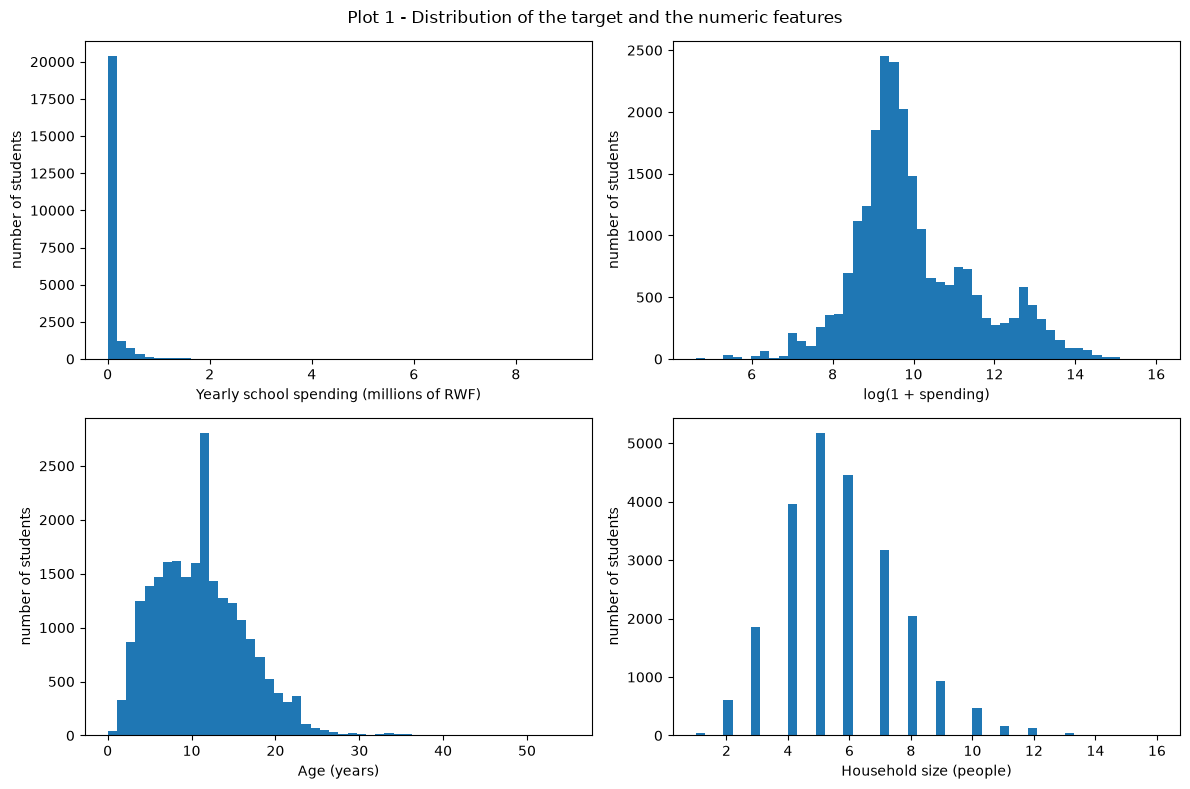

skewness before log: 11.11 | after log: 0.66


In [8]:
df["log_expenditure"] = np.log1p(df["expenditure"])

histograms = [
    (df["expenditure"] / 1_000_000, "Yearly school spending (millions of RWF)"),
    (df["log_expenditure"], "log(1 + spending)"),
    (df["age"], "Age (years)"),
    (df["household_size"], "Household size (people)"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (values, label) in zip(axes.ravel(), histograms):
    ax.hist(values, bins=50)
    ax.set_xlabel(label)
    ax.set_ylabel("number of students")
fig.suptitle("Plot 1 - Distribution of the target and the numeric features")
plt.tight_layout()
plt.show()

print("skewness before log:", round(df["expenditure"].skew(), 2), "| after log:", round(df["log_expenditure"].skew(), 2))

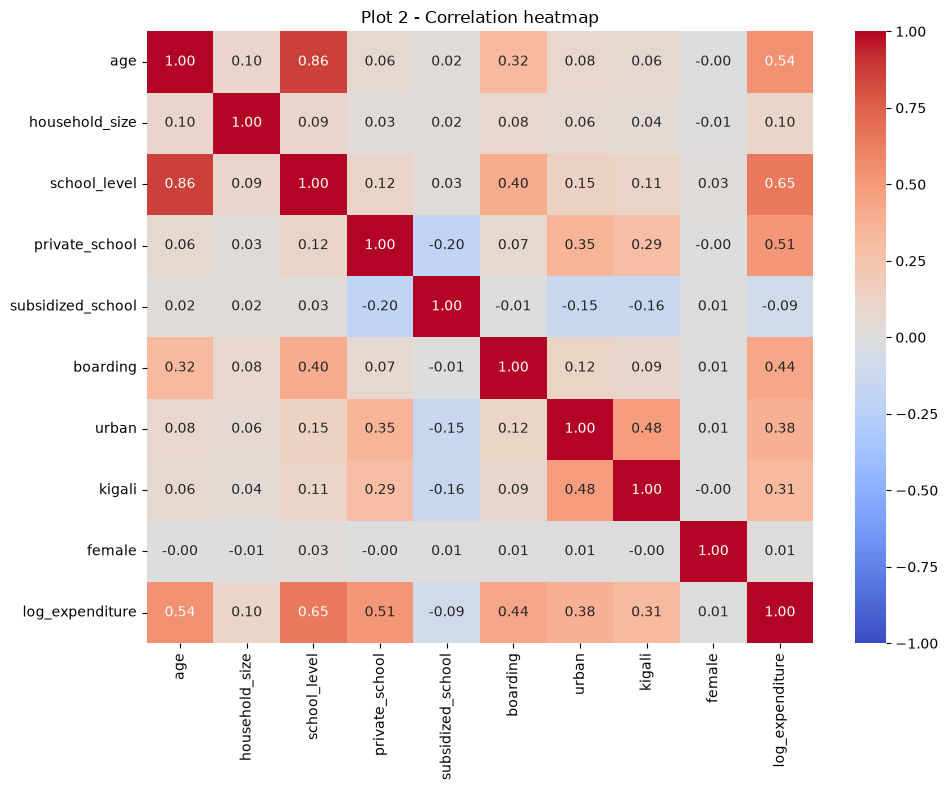

log_expenditure      1.00
school_level         0.65
age                  0.54
private_school       0.51
boarding             0.44
urban                0.38
kigali               0.31
household_size       0.10
female               0.01
subsidized_school   -0.09
Name: log_expenditure, dtype: float64


In [9]:
# yes/no versions of the categories so they can go in a correlation heatmap
heat = pd.DataFrame({
    "age": df["age"],
    "household_size": df["household_size"],
    "school_level": df["school_level"].map({level: i for i, level in enumerate(LEVEL_ORDER, start=1)}),
    "private_school": (df["school_type"] == "Private").astype(int),
    "subsidized_school": (df["school_type"] == "Government subsidized").astype(int),
    "boarding": (df["boarding"] == "Yes").astype(int),
    "urban": (df["area"] == "Urban").astype(int),
    "kigali": (df["province"] == "Kigali").astype(int),
    "female": (df["sex"] == "Female").astype(int),
    "log_expenditure": df["log_expenditure"],
})

plt.figure(figsize=(10, 8))
sns.heatmap(heat.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Plot 2 - Correlation heatmap")
plt.tight_layout()
plt.show()

print(heat.corr()["log_expenditure"].sort_values(ascending=False).round(2))

In [10]:
FEATURES = ["age", "sex", "province", "area", "school_level", "school_type", "boarding", "household_size", "payer"]
NUMERIC = ["age", "household_size"]
CATEGORICAL = ["sex", "province", "area", "school_level", "school_type", "boarding", "payer"]

# about 500 students (whole households) are kept aside as "new data" to upload to /retrain later
household_sizes = df.groupby("hhid").size().sample(frac=1, random_state=RANDOM_STATE)
new_households = household_sizes.index[household_sizes.cumsum() <= 500]

new_data = df[df["hhid"].isin(new_households)]
model_data = df[~df["hhid"].isin(new_households)]
new_data[FEATURES + ["expenditure"]].to_csv("../data/new_data_sample.csv", index=False)

print("new data rows:", len(new_data), "| rows left for modelling:", len(model_data))

new data rows: 499 | rows left for modelling: 22592


In [11]:
from sklearn.model_selection import GroupShuffleSplit


def split_by_household(x, y, households):
    # 80/20 split where every household is either fully in the first part or fully in the second
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
    first, second = next(splitter.split(x, y, groups=households))
    return x.iloc[first], x.iloc[second], y.iloc[first], y.iloc[second]


x = model_data[FEATURES]
y = model_data["log_expenditure"]
x_train, x_test, y_train, y_test = split_by_household(x, y, model_data["hhid"])

shared = set(model_data.loc[x_train.index, "hhid"]) & set(model_data.loc[x_test.index, "hhid"])
print("train rows:", len(x_train), "| test rows:", len(x_test))
print("households in both train and test:", len(shared))

train rows: 18082 | test rows: 4510
households in both train and test: 0


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# categories: fill the missing payer with the most common answer, then one 0/1 column per category
categories = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
# only the numeric columns are standardized; the 0/1 columns stay 0/1
preprocessor = ColumnTransformer([
    ("numbers", StandardScaler(), NUMERIC),
    ("categories", categories, CATEGORICAL),
])

x_train_s = preprocessor.fit_transform(x_train)   # learns means, stds and categories from train only
x_test_s = preprocessor.transform(x_test)
print("columns after encoding:", x_train_s.shape[1])

columns after encoding: 30


In [13]:
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

# a validation set is cut from the training set, so tuning never looks at the test set
x_tr, x_val, y_tr, y_val = split_by_household(x_train, y_train, model_data.loc[x_train.index, "hhid"])
x_tr_s = preprocessor.transform(x_tr)
x_val_s = preprocessor.transform(x_val)


def train_sgd(learning_rate, alpha, epochs, x_a, y_a, x_b, y_b):
    # one partial_fit call = one epoch; the MSE on both sets is stored after every epoch
    model = SGDRegressor(learning_rate="constant", eta0=learning_rate, alpha=alpha, random_state=RANDOM_STATE)
    losses_a, losses_b = [], []
    for epoch in range(epochs):
        model.partial_fit(x_a, y_a)
        losses_a.append(mean_squared_error(y_a, model.predict(x_a)))
        losses_b.append(mean_squared_error(y_b, model.predict(x_b)))
    return model, losses_a, losses_b

In [14]:
LEARNING_RATES = [0.0001, 0.001, 0.01, 0.05]
ALPHAS = [0.0001, 0.001, 0.01, 0.1]
CHECKPOINTS = [10, 50, 100]

rows = []
for learning_rate in LEARNING_RATES:
    for alpha in ALPHAS:
        _, _, val_losses = train_sgd(learning_rate, alpha, 100, x_tr_s, y_tr, x_val_s, y_val)
        for epochs in CHECKPOINTS:
            rows.append({"learning_rate": learning_rate, "alpha": alpha, "epochs": epochs,
                         "validation_mse": val_losses[epochs - 1]})

tuning = pd.DataFrame(rows)
best = tuning.loc[tuning["validation_mse"].idxmin()]
BEST_LR, BEST_ALPHA, BEST_EPOCHS = best["learning_rate"], best["alpha"], int(best["epochs"])
print("best learning rate:", BEST_LR, "| best alpha:", BEST_ALPHA, "| best epochs:", BEST_EPOCHS)
print("best validation MSE:", round(best["validation_mse"], 4))

best learning rate: 0.0001 | best alpha: 0.0001 | best epochs: 100
best validation MSE: 0.7344


In [15]:
# validation MSE after 100 epochs: learning rate (rows) against alpha (columns)
tuning[tuning["epochs"] == 100].pivot(index="learning_rate", columns="alpha", values="validation_mse").round(4)

alpha,0.0001,0.0010,0.0100,0.1000
learning_rate,,,,
0.0001,0.7344,0.7344,0.7451,0.8549
0.0010,0.7391,0.7377,0.7457,0.8569
0.0100,0.7866,0.7849,0.7905,0.8961
0.0500,0.8866,0.8835,0.8807,0.9554


In [16]:
# validation MSE with the best alpha: learning rate (rows) against number of epochs (columns)
tuning[tuning["alpha"] == BEST_ALPHA].pivot(index="learning_rate", columns="epochs", values="validation_mse").round(4)

epochs,10,50,100
learning_rate,,,
0.0001,0.8366,0.7439,0.7344
0.0010,0.7389,0.7391,0.7391
0.0100,0.7865,0.7866,0.7866
0.0500,0.8866,0.8866,0.8866


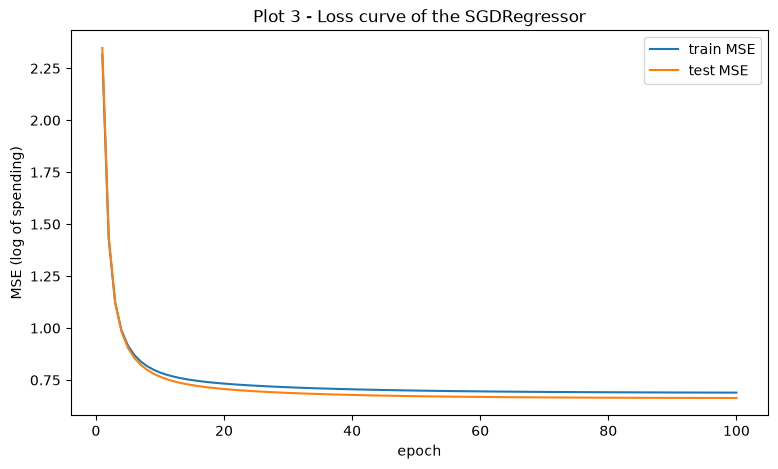

after epoch 1:  train 2.3154 | test 2.3477
after epoch 100 : train 0.6894 | test 0.6636


In [17]:
sgd, train_losses, test_losses = train_sgd(BEST_LR, BEST_ALPHA, BEST_EPOCHS, x_train_s, y_train, x_test_s, y_test)

plt.figure(figsize=(9, 5))
plt.plot(range(1, BEST_EPOCHS + 1), train_losses, label="train MSE")
plt.plot(range(1, BEST_EPOCHS + 1), test_losses, label="test MSE")
plt.xlabel("epoch")
plt.ylabel("MSE (log of spending)")
plt.title("Plot 3 - Loss curve of the SGDRegressor")
plt.legend()
plt.show()

print("after epoch 1:  train", round(train_losses[0], 4), "| test", round(test_losses[0], 4))
print("after epoch", BEST_EPOCHS, ": train", round(train_losses[-1], 4), "| test", round(test_losses[-1], 4))

In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

lin = LinearRegression().fit(x_train_s, y_train)

# the two linear models should predict almost the same values
sgd_pred = sgd.predict(x_test_s)
lin_pred = lin.predict(x_test_s)
print("correlation between the two predictions:", round(np.corrcoef(sgd_pred, lin_pred)[0, 1], 4))
print("average difference between the two predictions:", round(np.abs(sgd_pred - lin_pred).mean(), 4))
print("test MSE: SGDRegressor", round(mean_squared_error(y_test, sgd_pred), 4), "| LinearRegression", round(mean_squared_error(y_test, lin_pred), 4))

correlation between the two predictions: 0.9995
average difference between the two predictions: 0.0296
test MSE: SGDRegressor 0.6636 | LinearRegression 0.6624


In [19]:
def train_and_score(model):
    # fit on the small training part, report the error on it and on the validation part
    model.fit(x_tr_s, y_tr)
    return mean_squared_error(y_tr, model.predict(x_tr_s)), mean_squared_error(y_val, model.predict(x_val_s))


rows = []
for max_depth in [3, 5, 7, 10, 15]:
    for min_samples_leaf in [1, 10, 30]:
        tree_try = DecisionTreeRegressor(max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=RANDOM_STATE)
        train_mse, val_mse = train_and_score(tree_try)
        rows.append({"max_depth": max_depth, "min_samples_leaf": min_samples_leaf, "train_mse": train_mse, "validation_mse": val_mse})

tree_results = pd.DataFrame(rows).sort_values("validation_mse")
best_tree = tree_results.iloc[0]
tree_results.head().round(4)

,max_depth,min_samples_leaf,train_mse,validation_mse
7,7,10,0.5875,0.6649
10,10,10,0.5476,0.6695
11,10,30,0.5756,0.6705
8,7,30,0.6013,0.6708
6,7,1,0.5739,0.6747


In [20]:
rows = []
for min_samples_leaf in [1, 3, 5, 10]:
    for max_features in [1.0, 0.5]:
        forest_try = RandomForestRegressor(n_estimators=150, min_samples_leaf=min_samples_leaf, max_features=max_features,
                                           n_jobs=-1, random_state=RANDOM_STATE)
        train_mse, val_mse = train_and_score(forest_try)
        rows.append({"min_samples_leaf": min_samples_leaf, "max_features": max_features, "train_mse": train_mse, "validation_mse": val_mse})

forest_results = pd.DataFrame(rows).sort_values("validation_mse")
best_forest = forest_results.iloc[0]
forest_results.round(4)

,min_samples_leaf,max_features,train_mse,validation_mse
7,10,0.5,0.5092,0.6469
6,10,1.0,0.4939,0.6526
5,5,0.5,0.4514,0.6604
4,5,1.0,0.4298,0.6708
3,3,0.5,0.3919,0.6772
2,3,1.0,0.3667,0.6907
1,1,0.5,0.2211,0.7592
0,1,1.0,0.2223,0.7695


In [21]:
tree = DecisionTreeRegressor(max_depth=int(best_tree["max_depth"]), min_samples_leaf=int(best_tree["min_samples_leaf"]),
                             random_state=RANDOM_STATE).fit(x_train_s, y_train)
forest = RandomForestRegressor(n_estimators=150, min_samples_leaf=int(best_forest["min_samples_leaf"]),
                               max_features=float(best_forest["max_features"]), n_jobs=-1,
                               random_state=RANDOM_STATE).fit(x_train_s, y_train)

models = {
    "SGDRegressor": sgd,
    "LinearRegression": lin,
    "DecisionTreeRegressor": tree,
    "RandomForestRegressor": forest,
}

rows = []
for name, model in models.items():
    rows.append({"model": name,
                 "train_mse": mean_squared_error(y_train, model.predict(x_train_s)),
                 "test_mse": mean_squared_error(y_test, model.predict(x_test_s)),
                 "test_r2": r2_score(y_test, model.predict(x_test_s))})

results = pd.DataFrame(rows).sort_values("test_mse").reset_index(drop=True)
BEST_NAME = results.loc[0, "model"]

baseline = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
print("best model (lowest test MSE):", BEST_NAME)
print("baseline test MSE (always predict the average):", round(baseline, 4))
results.round(4)

best model (lowest test MSE): RandomForestRegressor
baseline test MSE (always predict the average): 2.3017


,model,train_mse,test_mse,test_r2
0,RandomForestRegressor,0.5192,0.6007,0.7389
1,DecisionTreeRegressor,0.6005,0.6285,0.7268
2,LinearRegression,0.6878,0.6624,0.7121
3,SGDRegressor,0.6894,0.6636,0.7116


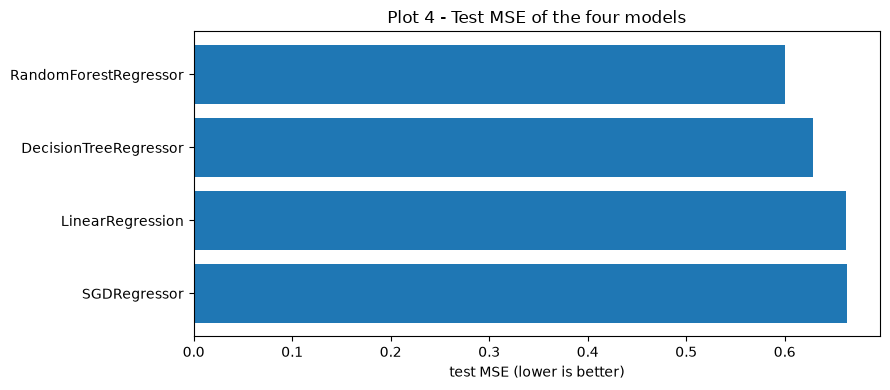

In [22]:
plt.figure(figsize=(9, 4))
plt.barh(results["model"][::-1], results["test_mse"][::-1])
plt.xlabel("test MSE (lower is better)")
plt.title("Plot 4 - Test MSE of the four models")
plt.tight_layout()
plt.show()